# Домашнее задание. Титаник
В этом домашнем задании вам предлагается решить задачу предсказания выживших пассажиров Титаника. Эту задачу машинного обучения рано или поздно решает, наверное, любой, кто обучается анализу данных. Информация о датасете доступна по <a href=https://www.kaggle.com/c/titanic>ссылке</a>.

Кстати, здесь же есть много готовых решений нашей задачи. Решение можно посмотреть в разделе <a href=https://www.kaggle.com/c/titanic/code>code на kaggle</a>.

Некоторые решения, которые уже есть:
https://www.kaggle.com/hacktech33/titanic-solution-xgboost (простое решение)

https://www.kaggle.com/shrutijhaa/in-top-3-titanic-machine-learning-from-disaster (возможно, слишком много визуализации, но хорошее качество)

https://www.kaggle.com/blackhurt/top-3-using-voting-classifier (сильное решение, использует метод простого голосования трёх сильных моделей)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

: 

## Загрузка данных

Загрузим датасет Titanic из приложенных файлов. В первом файле находится информация о пассажирах, во втором -- информация о том, выжил пассажир или нет.

Если вы запускаете ноутбук на Google Colab, самым простым способом загрузить данные в ноутбук будет примонтировать к Colab ваш Google Drive. Для этого сначала положите в свою корневую директорию Google Drive  файлы, приложенные к этому ноутбуку, а затем выполните три закоментированные строчки в клетке ниже. <a href=https://www.machinelearningmastery.ru/downloading-datasets-into-google-drive-via-google-colab-bcb1b30b0166/>Подробная инструкция по работе с Google Drive + Google Colab</a>

In [ ]:
#from google.colab import drive
#drive.mount('/content/gdrive/')
#data = pd.read_csv('/content/gdrive/My Drive/titanic_data.csv, index_col='PassengerId')

#Если запускаете ноутбук локально:
data = pd.read_csv('titanic_data.csv', index_col='PassengerId')

In [8]:
basic_features = data.columns

y = pd.read_csv('titanic_surv.csv')
y.index = data.index

print(f'Всего {len(data)} пассажиров в выборке')
data.head()

Всего 891 пассажиров в выборке


,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,
1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
y.head()

,Survived
PassengerId,
1,0
2,1
3,1
4,1
5,0


In [10]:
data = data.join(y)
data.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
PassengerId,,,,,,,,,,,
1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


## Исследование датасета

### Задание 1 (1 балл)
Опишите датасет. Сколько в нём мужчин, сколько женщин? Посчитайте распределение по классам пассажиров. Используйте функцию ``pd.Series.value_counts``. <a href=https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.value_counts.html>Пример использования</a>

Посчитайте долю выживших мужчин к общему количеству мужчин, а также женщин к общему количеству женщин. Сделайте выводы. 
Проведите схожую аналитику по возрасту выживших и по классу выживших. 

Вам поможет функция ``plt.hist()``. <a href=https://matplotlib.org/3.3.1/gallery/pyplots/pyplot_text.html#sphx-glr-gallery-pyplots-pyplot-text-py> Пример использования </a> 

Sex
male      577
female    314
Name: count, dtype: int64
0.18890814558058924
0.7420382165605095


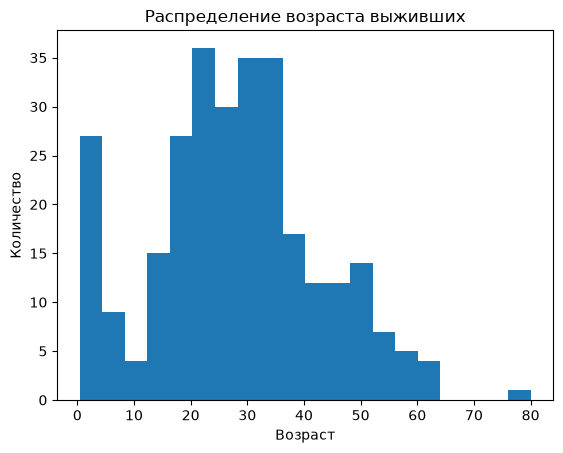

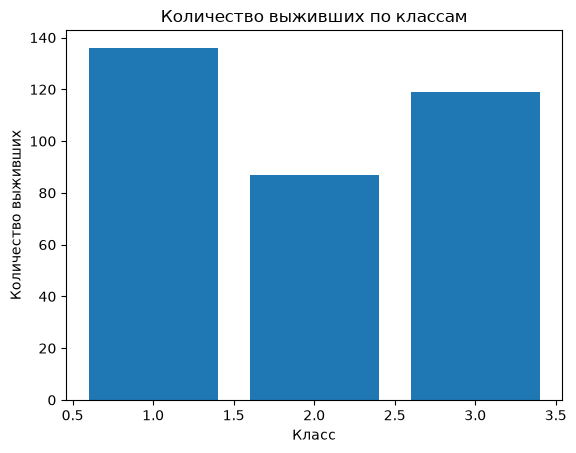

In [11]:
counts = data['Sex'].value_counts()
print(counts)

data['Pclass'].value_counts()

men = data[data['Sex'] == 'male']
men_survived = men['Survived'].mean()

print(men_survived)

woman = data[data['Sex'] == 'female']
woman_survived = woman['Survived'].mean()

print(woman_survived)

#выжило больше женщин

import matplotlib.pyplot as plt

survived = data[data['Survived'] == 1]

plt.hist(survived['Age'].dropna(), bins=20)
plt.title('Распределение возраста выживших')
plt.xlabel('Возраст')
plt.ylabel('Количество')
plt.show()

survived_by_class = data[data['Survived'] == 1]['Pclass'].value_counts().sort_index()

plt.bar(survived_by_class.index, survived_by_class.values)
plt.title('Количество выживших по классам')
plt.xlabel('Класс')
plt.ylabel('Количество выживших')
plt.show()






## Заполнение пропусков в данных
В данных имеются пропуски в трёх колонках: 

In [12]:
data.columns[data.isna().any()].tolist()

['Age', 'Cabin', 'Embarked']

Для простоты заполним все пропуски в категориальных колонках новым классом "0", а в числовой колонке Age --- медианным значением. 

In [13]:
data.loc[:, ['Cabin', 'Embarked']] = data.loc[:, ['Cabin', 'Embarked']].fillna('0')
data['Age'] = data['Age'].fillna(data['Age'].median())

## Подготовка плана тестирования

### Задание 2. (0 баллов)
Разделите выборку на обучающее и тестовое множество в соотношении 70:30.

In [14]:
from sklearn.model_selection import train_test_split
data_train, data_test = train_test_split(data, test_size=0.3, random_state=42)

## Выделение новых признаков
Теперь отложим тестовые данные и приступим к моделированию. Внимательно изучите данные. Можете ли вы выделить признаки, которые не указаны явно в таблице?

### Задание 3 (1 балл)
 Сформируйте по крайней мере один новый признак и объясните ваш выбор. Пример признака сформирован за вас. 

Указания: 
- Пассажиров можно поделить на несколько классов по их именам.
- Различных номеров кают слишком много. Но буквы в номерах кают указывают на их местоположение. (***Этот признак сформирован в примере***)
- Возможно, имеет смысл отделить мальчиков от мужчин. Отделять девочек от женщин может быть не так важно
- Другие идеи для признаков можно почерпнуть на форуме в обсуждении задачи на kaggle.com.

In [15]:
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1 

In [16]:
data['FamilySize']

PassengerId
1      2
2      2
3      1
4      2
5      1
      ..
887    1
888    1
889    4
890    1
891    1
Name: FamilySize, Length: 891, dtype: int64

Сюда добавьте описание вашего нового признака

In [18]:
# Новый признак - [FamilySize] - кол-во членов семьи пассажира, включая его самого. Предполагаю, что этот признак мог влиять на выживаемость пассажиров.
# Рассчитывается, как SibSp - братья/сестры + Parch - родители/дети + 1 - сам пассажир

## Кодирование категориальных признаков и обработка данных
Все признаки сейчас делятся на числовые, бинарные, категориальные и текстовые. К текстовым признакам можно отнести имя пассажира, номер билета и номер каюты: значения этих признаков уникальны почти для всех пассажиров, и простого способа использовать их в модели не существует.

### Задание 4 (0 баллов)
Пока используя только изначальные признаки, перекодируйте категориальные признаки функцией ``pd.get_dummies``. Естественно, имена пассажиров и номера билетов и кают кодировать не стоит, поскольку все значения этих признаков уникальные. 

In [19]:
data_encoded = pd.get_dummies(
    data,
    columns=['Sex', 'Embarked'],
    drop_first=True         #это убирает столбец с незакодированным признаком
)

data_encoded.head()

,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Survived,FamilySize,Sex_male,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,,,,
1,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,0,2,True,False,False,True
2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,1,2,False,True,False,False
3,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,0,1,1,False,False,False,True
4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,1,2,False,False,False,True
5,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,0,1,True,False,False,True


## Обучение baseline-модели

### Задание 5 (1 балл)

Обучите одну из простых известных вам моделей. Измерьте качество полученной модели на кросс-валидации (используйте только обучающую выборку!)

In [23]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split

train, test = train_test_split(data_encoded, test_size=0.3, random_state=42)

X_train = data_encoded.drop(['Survived', 'Name', 'Ticket', 'Cabin'], axis=1)    #все данные, кроме ответа. еще убрала уникальные текстовые признаки, с ними не получалось
y_train = data_encoded['Survived']                 #только ответы

model = LogisticRegression(max_iter=1000)    

scores = cross_val_score(model, X_train, y_train, cv=5)  #cv=5 - поделила данные на 5 частей, при кросс-валидации каждая из них в одном заходе побывает проверочной, а остальные тренировочными

print("Точность на кросс-валидации:", scores.mean())

Точность на кросс-валидации: 0.7890151277383717


### Задание 6 (1 балл)
Добавьте в модель два новых сгенерированных признака. Если нужно, добавьте признаки, сгенерированные ohe-hot кодированием. Обучите ту же самую модель на расширенном множестве признаков. Улучшилось ли качество предсказания на кросс-валидации?

In [ ]:
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)
data['AgeGroup'] = (data['Age'] < 18).astype(int)

data_encoded = pd.get_dummies(data, columns=['Sex', 'Embarked'], drop_first=True)    #заново закодировала колонки в обновленном датасете

train, test = train_test_split(data_encoded, test_size=0.3, random_state=42)

X_train = train.drop(['Survived', 'Name', 'Ticket', 'Cabin'], axis=1)
y_train = train['Survived']

model = LogisticRegression(max_iter=1000)

scores = cross_val_score(model, X_train, y_train, cv=5)

print("Новая точность:", scores.mean())

#да, улучшилось

Новая точность: 0.8057032258064517


## Дополнительное моделирование
### Задание 7 (2 балла)
Теперь более серьёзно подойдём к моделированию. Попробуйте несколько алгоритмов из тех, что мы проходили в курсе. Вам помогут ноутбуки с линейными алгоритмами и выбором модели. Хотя бы для одного алгоритма проведите подбор оптимального гиперпараметра. 

In [28]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Forest": RandomForestClassifier(),
    "Boosting": GradientBoostingClassifier()
}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5)
    print(name, scores.mean())

Forest 0.7833935483870968
Boosting 0.8266451612903225


## Результаты моделирования

### Задание 8 (1 балл)
Измерьте качество итоговой модели на кросс-валидации. Выполните предсказание на тестовом множестве и сохраните их в переменную ``y_test``. Измерьте итоговое качество на тестовом множестве.

In [ ]:
from sklearn.metrics import accuracy_score

X_train = train.drop('Survived', axis=1)
y_train = train['Survived']

X_test = test.drop('Survived', axis=1)
y_test = test['Survived']

# обучаем  на train выборке
model.fit(X_train, y_train)

# предсказания на test
y_pred = model.predict(X_test)

# точность
test_accuracy = accuracy_score(y_test, y_pred)

print("Точность на тестовой выборке:", test_accuracy)

## Выводы
### Задание 9 (3 балла)
Сделайте выводы. Какие из идей сработали? Какие оказались лишними?

Была проведена предобработка датасета, закодированы категориальные признаки, и добавлены новые, причем после добавления трех новых признаков качество модели немного улучшилось. Самым полезным из добавленных признаков оказался IsAlone - путешествует ли человек один. Модель логистической регрессии показала стабильный результат, но скорее всего можно было бы добиться еще лучшего более сложной моделью (например бустингом)